In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, img_as_float, color
from skimage.segmentation import morphological_chan_vese, checkerboard_level_set
from skimage.restoration import denoise_tv_chambolle
from skimage.restoration import denoise_tv_bregman

In [26]:
# Helpers

def load_gray(path):
    img = io.imread(path)
    if img.ndim == 3:
        img = color.rgb2gray(img[..., :3])
    return img_as_float(img)

images = {
    "Artery":      load_gray("Artery.jpg"),
    "Cryo-EM":     load_gray("Cryo_EM_Image2.png"),
}

def normalize(seg):
    seg = seg.astype(bool)
    return seg if seg.mean() <= 0.5 else ~seg

ACWE with a snapshot every 10 iterations

In [27]:
def run_acwe(img, n_iter=100, step=10, smoothing=3, lambda1=1, lambda2=1, init=None):
    snaps = {}
    counter = {"k": 0}

    def cb(ls):
        counter["k"] += 1
        if counter["k"] % step == 0:
            snaps[counter["k"]] = ls.copy()

    init = checkerboard_level_set(img.shape, 6) if init is None else init
    final = morphological_chan_vese(
        img, num_iter=n_iter, init_level_set=init,
        smoothing=smoothing, lambda1=lambda1, lambda2=lambda2,
        iter_callback=cb)

    return snaps, normalize(final)

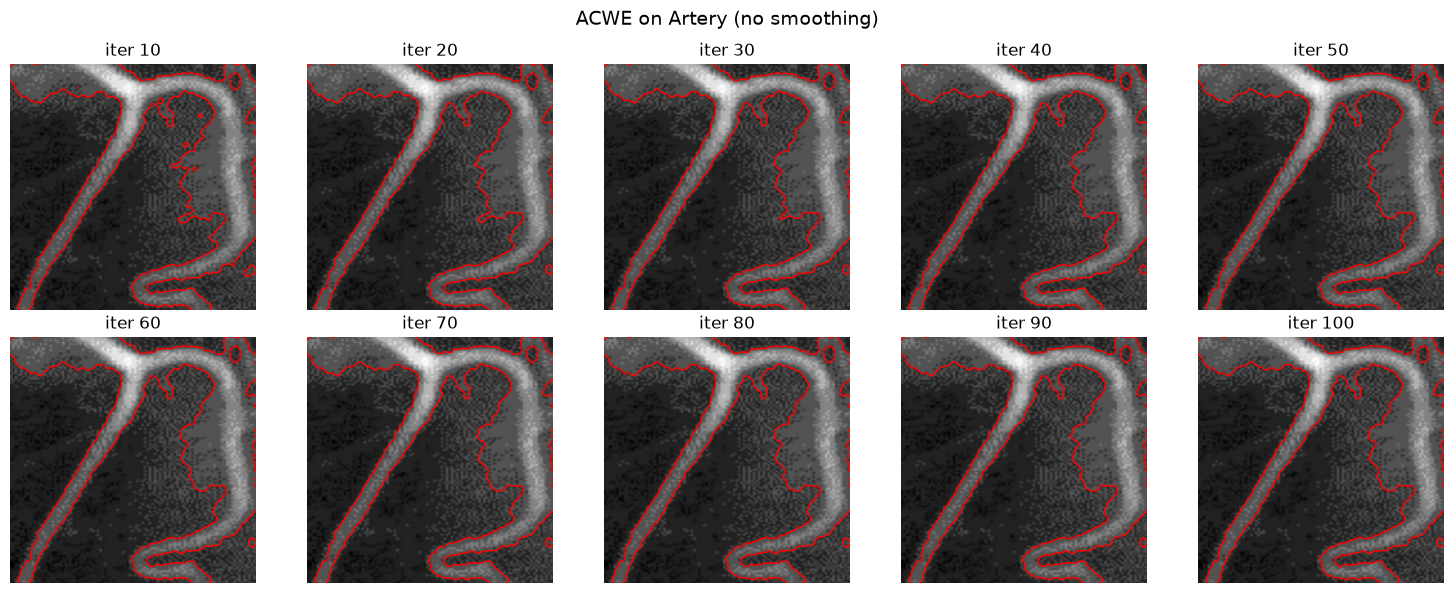

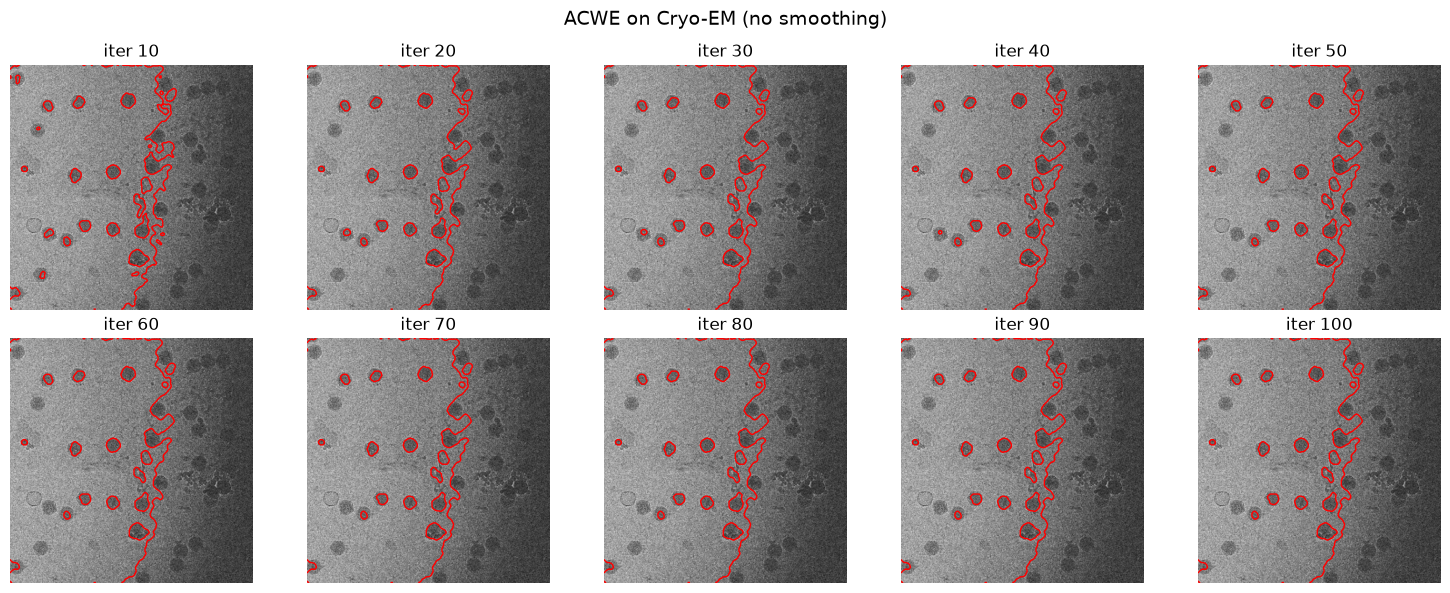

In [28]:
def show_snaps(img, snaps, title):
    its = sorted(snaps)
    cols = 5
    rows = int(np.ceil(len(its) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3*cols, 3*rows))
    for ax, k in zip(axes.ravel(), its):
        ax.imshow(img, cmap="gray")
        ax.contour(snaps[k], [0.5], colors="r", linewidths=1)
        ax.set_title(f"iter {k}")
        ax.axis("off")
    for ax in axes.ravel()[len(its):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

results_raw = {}
for name, img in images.items():
    snaps, final = run_acwe(img, n_iter=100, step=10)
    results_raw[name] = (snaps, final)
    show_snaps(img, snaps, f"ACWE on {name} (no smoothing)")

TV smoothing, then repeat

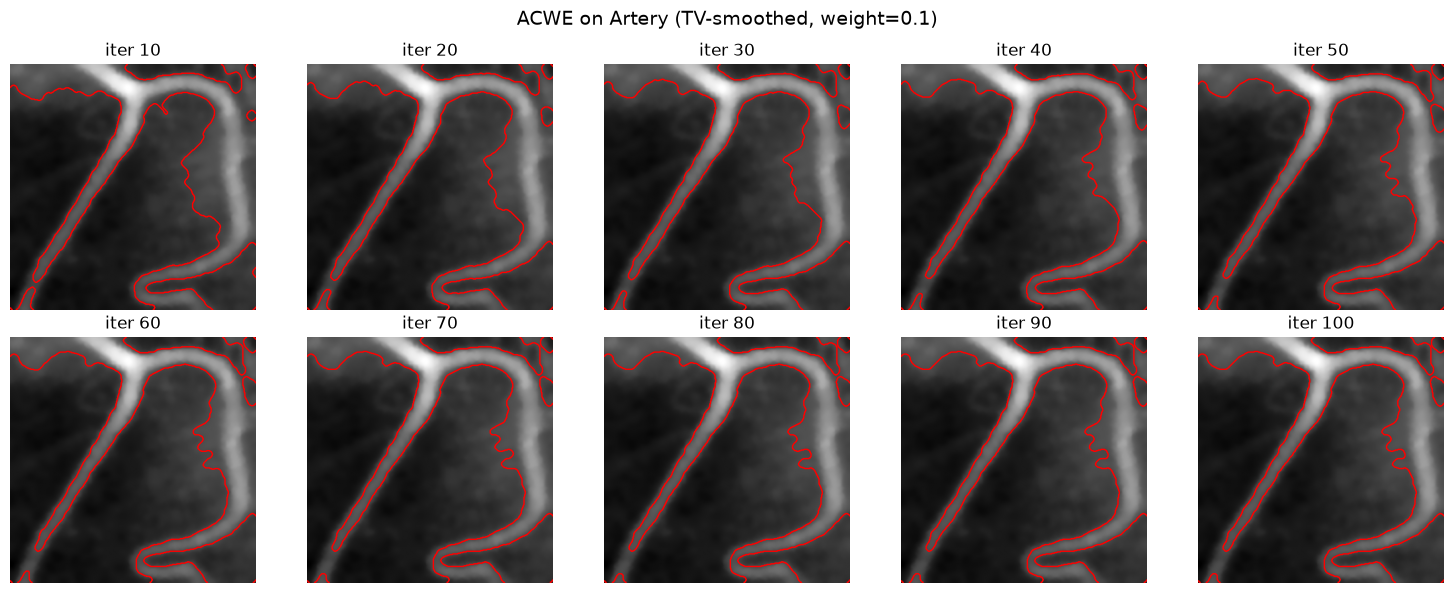

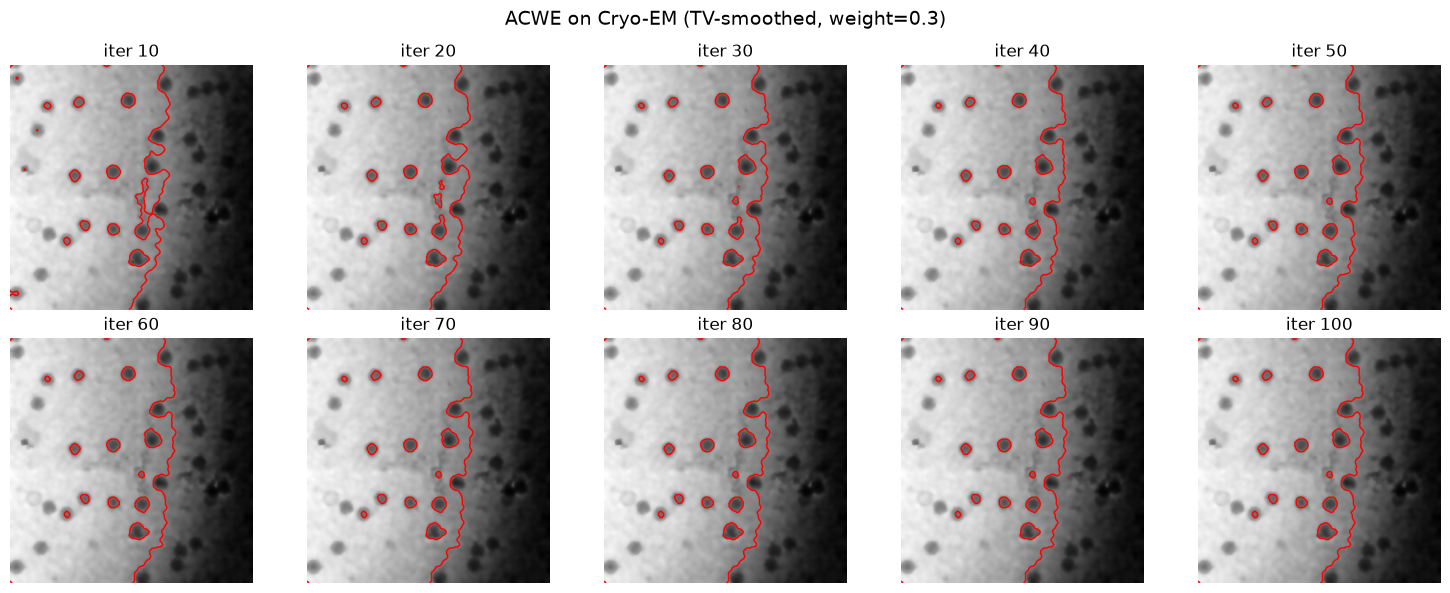

In [29]:
def tv_smooth(img, weight=0.1):
    return denoise_tv_chambolle(img, weight=weight)

weights = {"Artery": 0.1, "Cryo-EM": 0.3}   # Cryo-EM is very noisy, so use a stronger weight

results_tv = {}
smoothed = {}
for name, img in images.items():
    smoothed[name] = tv_smooth(img, weights[name])
    snaps, final = run_acwe(smoothed[name], n_iter=100, step=10)
    results_tv[name] = (snaps, final)
    show_snaps(smoothed[name], snaps, f"ACWE on {name} (TV-smoothed, weight={weights[name]})")

Compare the two

In [36]:
def dice(a, b):
    a, b = a.astype(bool), b.astype(bool)
    def _dice(x, y):
        return 2 * (x & y).sum() / (x.sum() + y.sum() + 1e-9)
    return max(_dice(a, b), _dice(a, ~b))


Artery
  raw:           regions=   2  fg area=0.356
  TV (Bregman)   regions=   4  fg area=0.201  Dice vs raw=0.722
  Perona-Malik   regions=   6  fg area=0.277  Dice vs raw=0.858

Cryo-EM
  raw:           regions=  25  fg area=0.429
  TV (Bregman)   regions=  12  fg area=0.411  Dice vs raw=0.967
  Perona-Malik   regions=  17  fg area=0.396  Dice vs raw=0.956


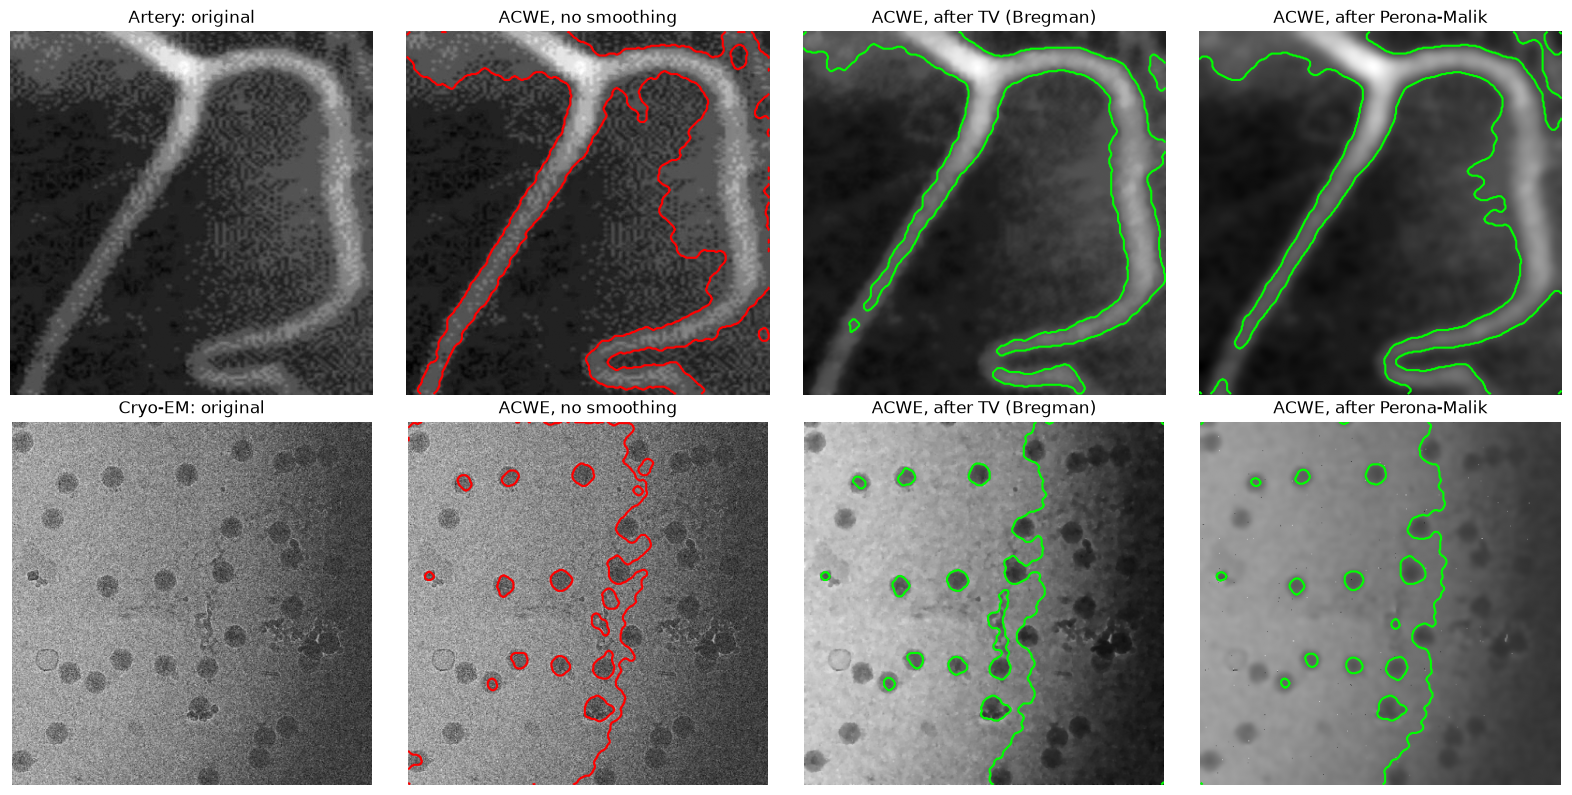

In [38]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for r, name in enumerate(images):
    img = images[name]
    raw = results_raw[name][1]

    # column 0: original
    axes[r, 0].imshow(img, cmap="gray")
    axes[r, 0].set_title(f"{name}: original")

    # column 1: ACWE on raw image
    axes[r, 1].imshow(img, cmap="gray")
    axes[r, 1].contour(raw, [0.5], colors="red")
    axes[r, 1].set_title("ACWE, no smoothing")

    print(f"\n{name}")
    print(f"  raw:           regions={label(raw).max():4d}  fg area={raw.mean():.3f}")

    # columns 2-3: one per smoother
    for c, sname in enumerate(smoothers, start=2):
        s = smoothed[(name, sname)]
        seg = results[(name, sname)][1]
        axes[r, c].imshow(s, cmap="gray")
        axes[r, c].contour(seg, [0.5], colors="lime")
        axes[r, c].set_title(f"ACWE, after {sname}")
        print(f"  {sname:14s} regions={label(seg).max():4d}  fg area={seg.mean():.3f}  "
              f"Dice vs raw={dice(raw, seg):.3f}")

    for a in axes[r]:
        a.axis("off")

plt.tight_layout()
plt.show()

Smooth the image with total variation image smoothing (per midterm) and repear
(b) and report the difference.

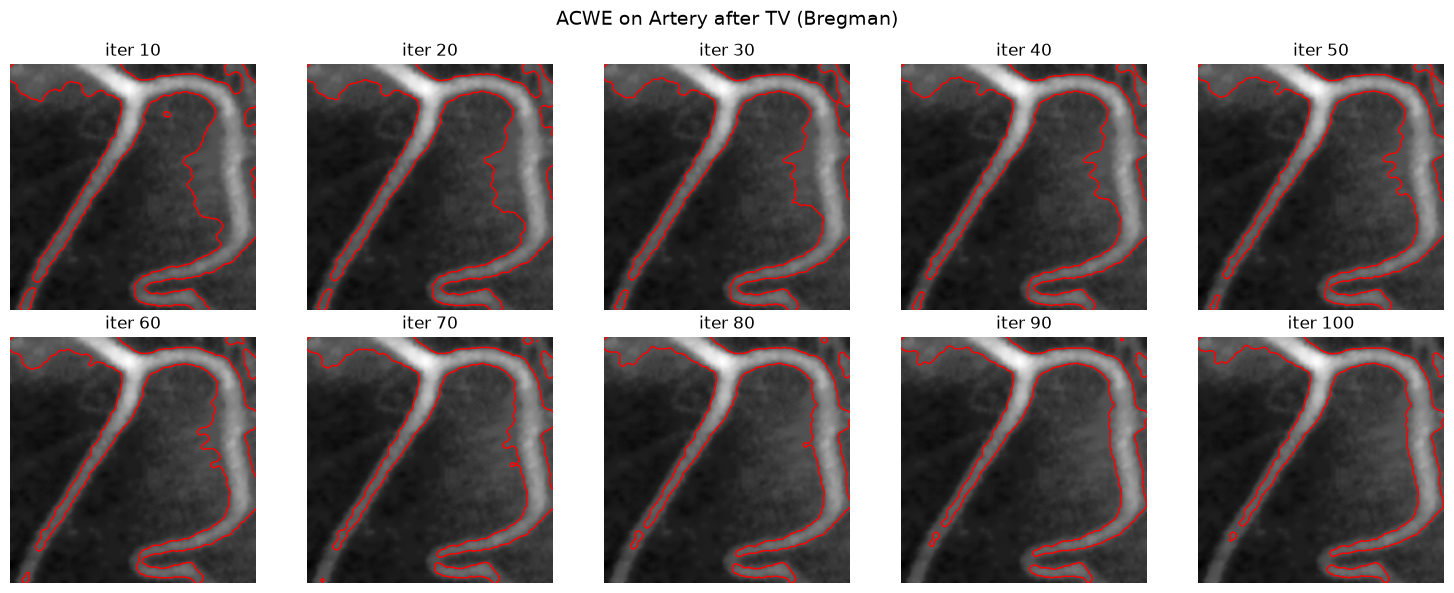

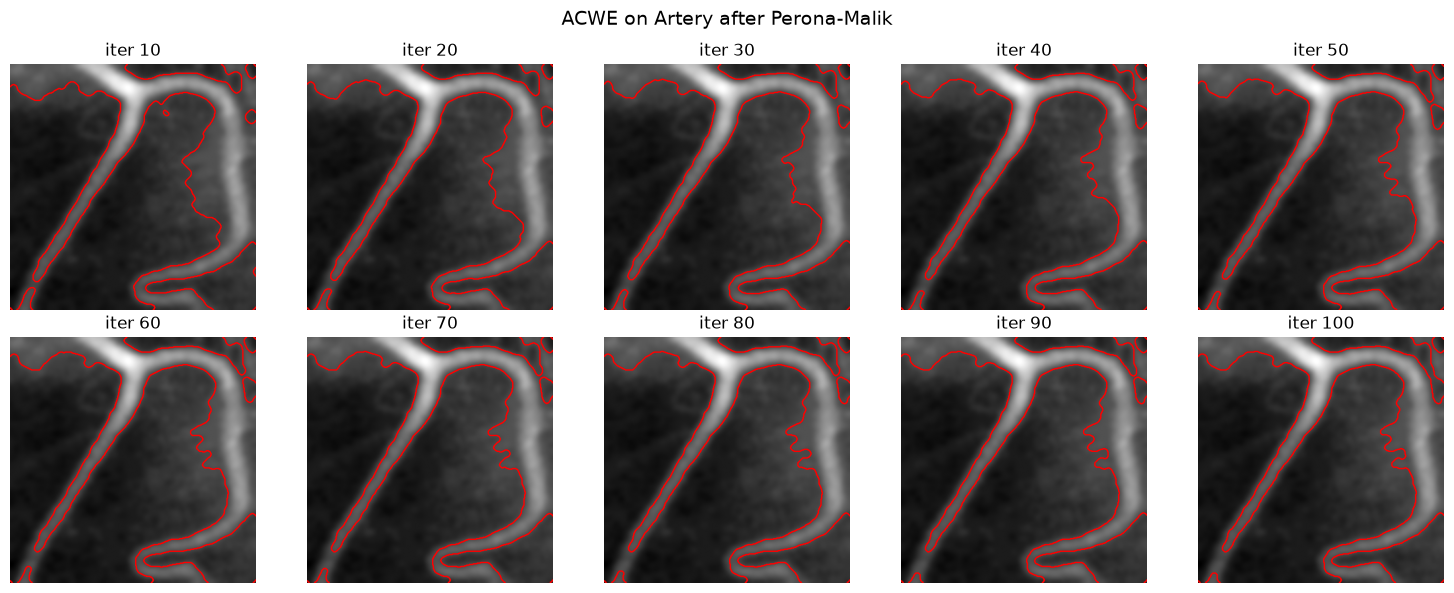

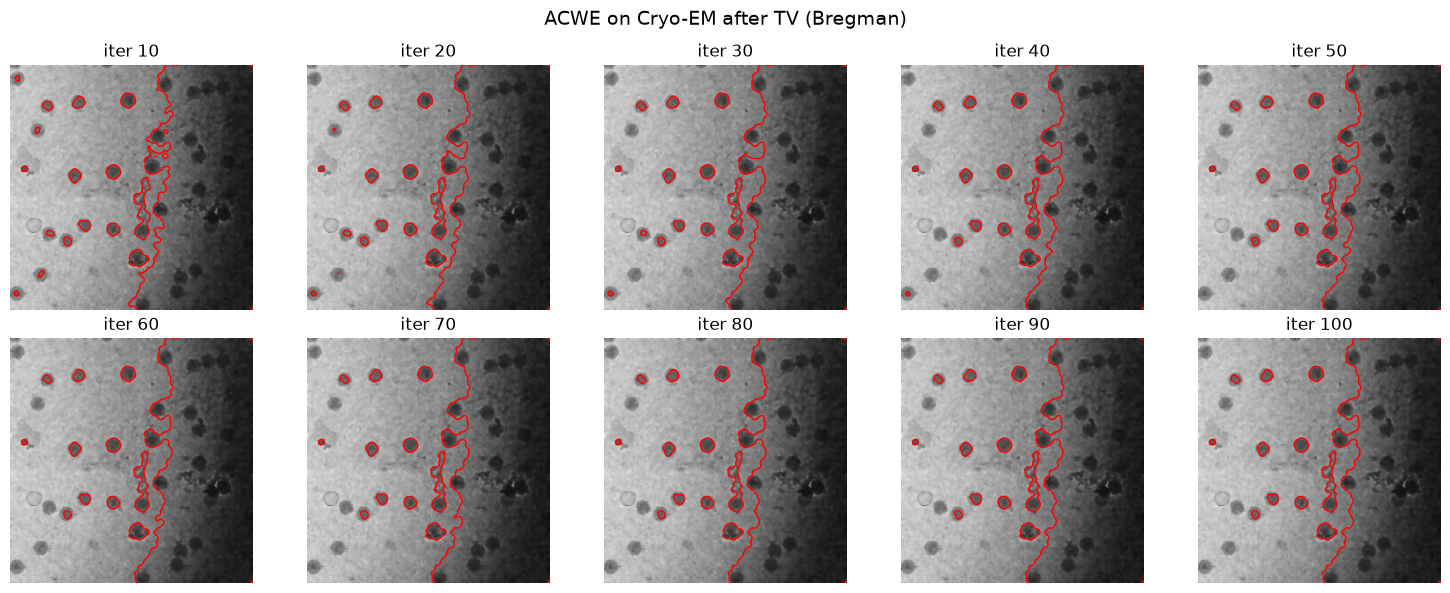

In [ ]:
# From midterm code
def perona_malik(img, n_iter=40, kappa=0.1, gamma=0.2):
    u = img.copy()
    g = lambda d: np.exp(-(d / kappa) ** 2)
    for _ in range(n_iter):
        p = np.pad(u, 1, mode='edge')
        dN = p[:-2, 1:-1] - u; dS = p[2:, 1:-1] - u
        dE = p[1:-1, 2:] - u;  dW = p[1:-1, :-2] - u
        u = u + gamma * (g(dN)*dN + g(dS)*dS + g(dE)*dE + g(dW)*dW)
    return u

# denoise_tv_bregman: larger weight = LESS smoothing (opposite of Chambolle)
smoothers = {
    "TV (Bregman)":   lambda im: denoise_tv_bregman(im, weight=5),
    "Perona-Malik":   lambda im: perona_malik(im, n_iter=40, kappa=0.1, gamma=0.2),
}

smoothed, results = {}, {}
for name, img in images.items():
    for sname, f in smoothers.items():
        s = f(img)
        smoothed[(name, sname)] = s
        snaps, final = run_acwe(s, n_iter=100, step=10)
        results[(name, sname)] = (snaps, final)
        show_snaps(s, snaps, f"ACWE on {name} after {sname}")

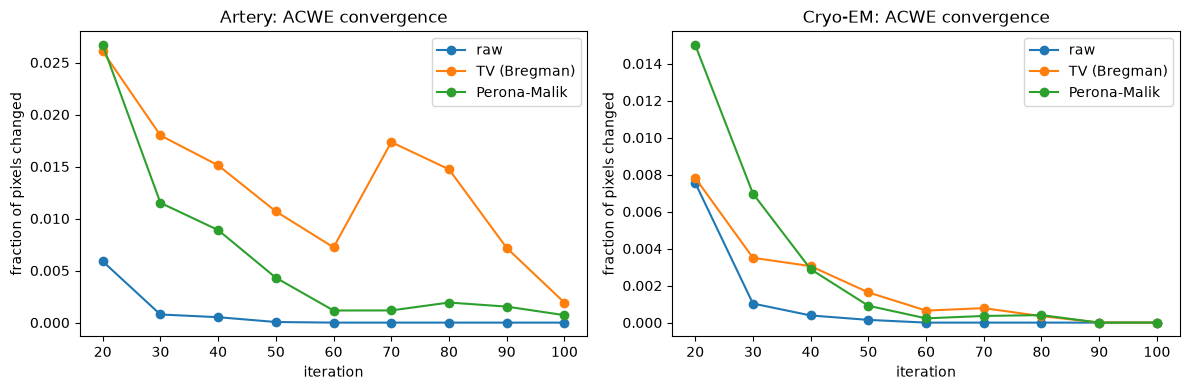

In [39]:
def convergence(snaps):
    its = sorted(snaps)
    return its[1:], [np.mean(snaps[b] != snaps[a]) for a, b in zip(its[:-1], its[1:])]

fig, axes = plt.subplots(1, len(images), figsize=(6 * len(images), 4))
for ax, name in zip(np.atleast_1d(axes), images):
    k, d = convergence(results_raw[name][0])
    ax.plot(k, d, "o-", label="raw")
    for sname in smoothers:
        k, d = convergence(results[(name, sname)][0])
        ax.plot(k, d, "o-", label=sname)
    ax.set_title(f"{name}: ACWE convergence")
    ax.set_xlabel("iteration")
    ax.set_ylabel("fraction of pixels changed")
    ax.legend()
plt.tight_layout()
plt.show()


Artery
  raw:           regions=   2  fg area=0.356
  TV (Bregman)   regions=   4  fg area=0.201  Dice vs raw=0.722
  Perona-Malik   regions=   6  fg area=0.277  Dice vs raw=0.858

Cryo-EM
  raw:           regions=  25  fg area=0.429
  TV (Bregman)   regions=  12  fg area=0.411  Dice vs raw=0.967
  Perona-Malik   regions=  17  fg area=0.396  Dice vs raw=0.956


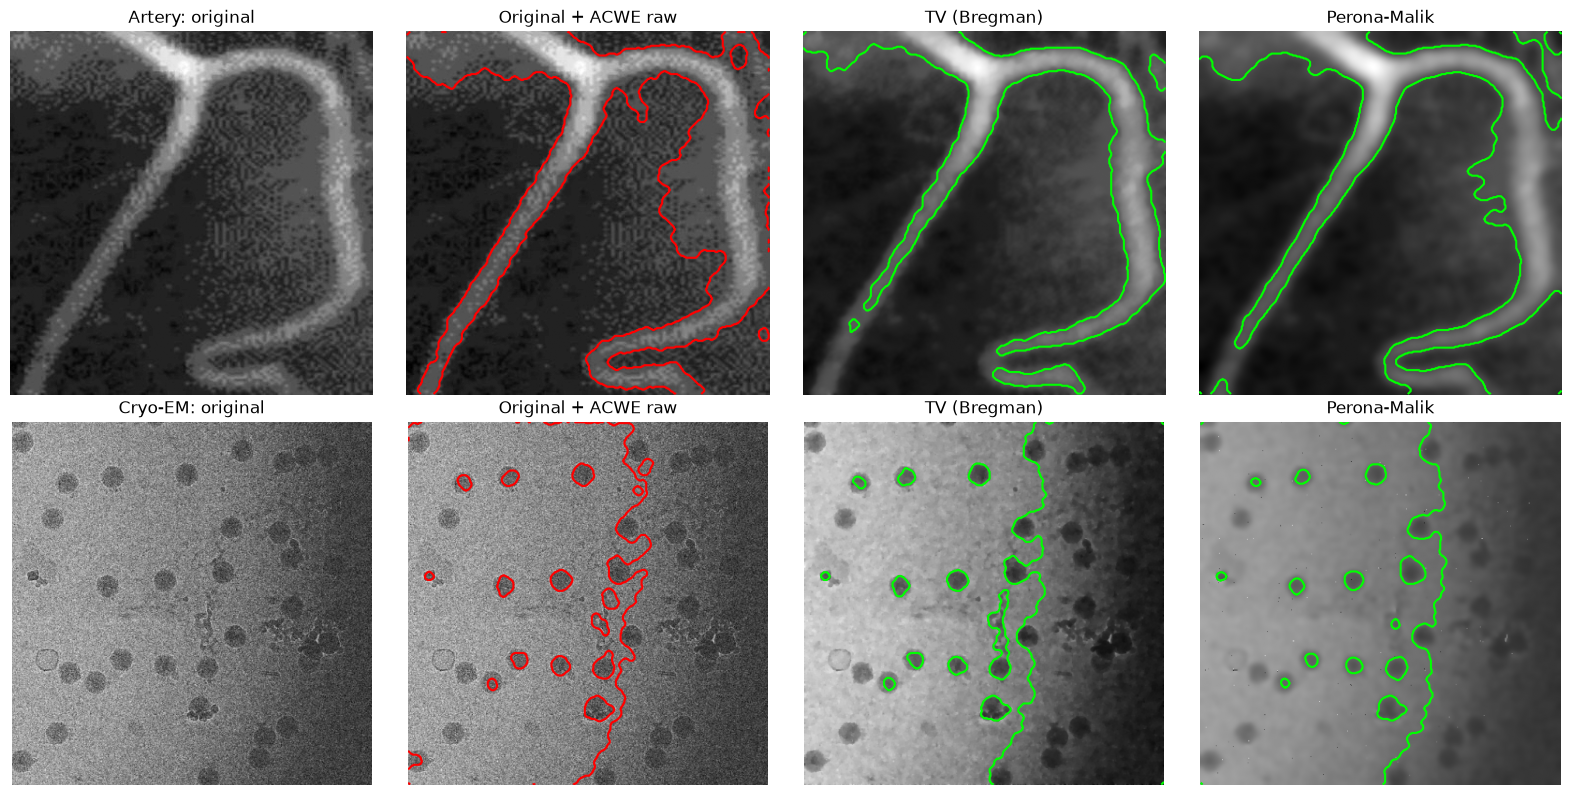

In [43]:
from skimage.measure import label

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for r, name in enumerate(images):
    img = images[name]
    raw = results_raw[name][1]
    panels = [("Original + ACWE raw", img, raw, "red")]
    for sname in smoothers:
        panels.append((f"{sname}", smoothed[(name, sname)], results[(name, sname)][1], "lime"))
    axes[r, 0].imshow(img, cmap="gray"); axes[r, 0].set_title(f"{name}: original"); axes[r, 0].axis("off")
    for c, (t, bg, seg, col) in enumerate(panels, start=1):
        axes[r, c].imshow(bg, cmap="gray"); axes[r, c].contour(seg, [0.5], colors=col)
        axes[r, c].set_title(t); axes[r, c].axis("off")
    print(f"\n{name}")
    print(f"  raw:           regions={label(raw).max():4d}  fg area={raw.mean():.3f}")
    for sname in smoothers:
        seg = results[(name, sname)][1]
        print(f"  {sname:14s} regions={label(seg).max():4d}  fg area={seg.mean():.3f}  "
              f"Dice vs raw={dice(raw, seg):.3f}")
plt.tight_layout(); plt.show()

## Motion

In [ ]:
I1 = images["Artery"]                                    
I2 = ndi.shift(I1, shift=(0, 1), order=1, mode="nearest")  # (rows, cols): +1 pixel in x (to the right)

In [10]:
def affine_flow(I1, I2, sigma=2.0, n_iter=6, margin=8):
    H, W = I1.shape
    ys, xs = np.mgrid[0:H, 0:W].astype(float)

    # normalized, centered coordinates for good conditioning
    cx, cy, s = W / 2, H / 2, max(H, W) / 2
    xn, yn = (xs - cx) / s, (ys - cy) / s

    mask = (xs >= margin) & (xs < W - margin) & (ys >= margin) & (ys < H - margin)

    I1s = ndi.gaussian_filter(I1, sigma)
    I2s = ndi.gaussian_filter(I2, sigma)

    p = np.zeros(6)          # [p0..p5] in normalized coordinates
    history = []

    for it in range(n_iter):
        # current flow field
        u = p[0] + p[1] * xn + p[2] * yn
        v = p[3] + p[4] * xn + p[5] * yn

        # warp I2 back toward I1:  I2w(x,y) = I2(x+u, y+v)
        I2w = ndi.map_coordinates(I2s, [ys + v, xs + u], order=1, mode="nearest")

        # derivatives: average the gradients of the two aligned frames
        Iy1, Ix1 = np.gradient(I1s)
        Iy2, Ix2 = np.gradient(I2w)
        Ix, Iy = 0.5 * (Ix1 + Ix2), 0.5 * (Iy1 + Iy2)
        It = I2w - I1s

        # one equation per pixel in the 6 increments
        A = np.stack([Ix, Ix * xn, Ix * yn, Iy, Iy * xn, Iy * yn], axis=-1)[mask]
        b = -It[mask]
        dp, *_ = np.linalg.lstsq(A, b, rcond=None)
        p = p + dp

        history.append((np.sqrt(np.mean(It[mask] ** 2)), p.copy()))

    # convert normalized parameters back to pixel units
    a = np.array([
        p[0] - p[1] * cx / s - p[2] * cy / s,   # a1 (translation in x)
        p[1] / s,                               # a2
        p[2] / s,                               # a3
        p[3] - p[4] * cx / s - p[5] * cy / s,   # a4 (translation in y)
        p[4] / s,                               # a5
        p[5] / s,                               # a6
    ])
    u = a[0] + a[1] * xs + a[2] * ys
    v = a[3] + a[4] * xs + a[5] * ys
    return a, u, v, mask, history, I2w, I1s

In [11]:
a, u, v, mask, history, I2w, I1s = affine_flow(I1, I2)

names = ["a1 (u: const)", "a2 (u: x)", "a3 (u: y)", "a4 (v: const)", "a5 (v: x)", "a6 (v: y)"]
truth = [1, 0, 0, 0, 0, 0]
for n, est, t in zip(names, a, truth):
    print(f"{n:15s} estimated = {est: .4f}   true = {t}")

epe = np.sqrt((u - 1) ** 2 + v ** 2)[mask].mean()
print(f"\nmean endpoint error = {epe:.4f} px")
print("RMS brightness residual per iteration:",
      [f"{h[0]:.5f}" for h in history])

a1 (u: const)   estimated =  1.0000   true = 1
a2 (u: x)       estimated =  0.0000   true = 0
a3 (u: y)       estimated =  0.0000   true = 0
a4 (v: const)   estimated = -0.0000   true = 0
a5 (v: x)       estimated = -0.0000   true = 0
a6 (v: y)       estimated =  0.0000   true = 0

mean endpoint error = 0.0000 px
RMS brightness residual per iteration: ['0.00325', '0.00010', '0.00000', '0.00000', '0.00000', '0.00000']


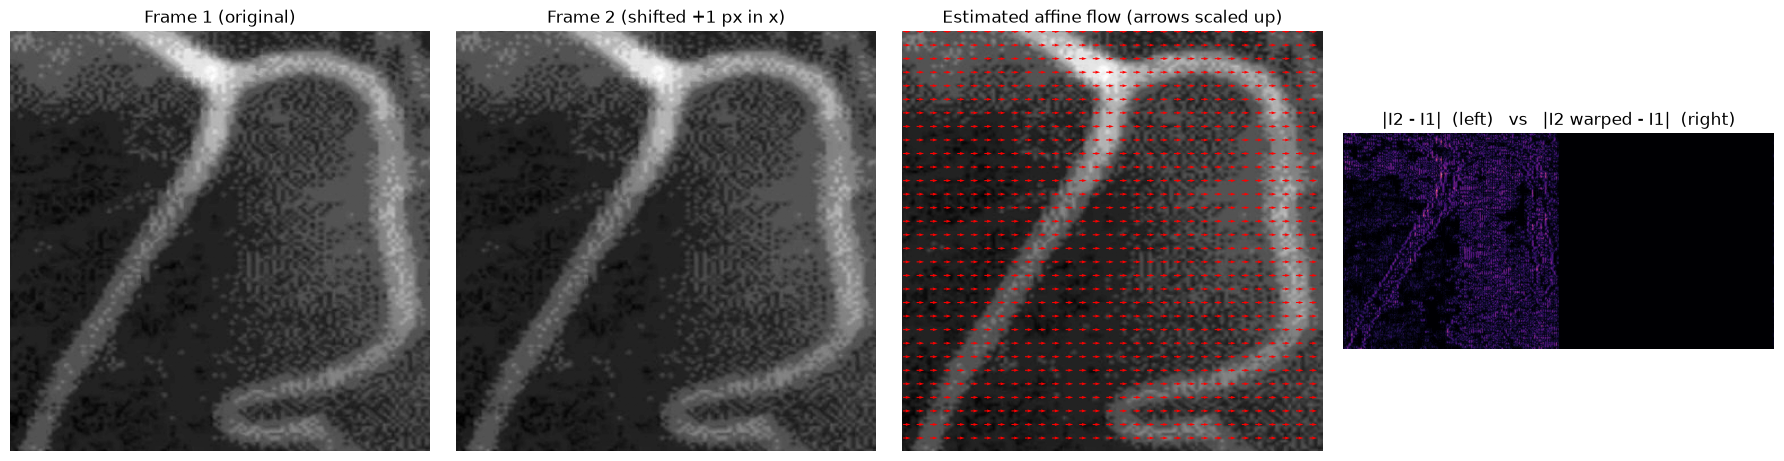

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

axes[0].imshow(I1, cmap="gray"); axes[0].set_title("Frame 1 (original)")
axes[1].imshow(I2, cmap="gray"); axes[1].set_title("Frame 2 (shifted +1 px in x)")

step = 12
H, W = I1.shape
yy, xx = np.mgrid[0:H:step, 0:W:step]
axes[2].imshow(I1, cmap="gray")
axes[2].quiver(xx, yy, u[::step, ::step], v[::step, ::step],
               color="red", angles="xy", scale_units="xy", scale=0.15)
axes[2].set_title("Estimated affine flow (arrows scaled up)")

diff_before = np.abs(I2 - I1)
diff_after = np.abs(I2w - I1s)
axes[3].imshow(np.hstack([diff_before, diff_after]), cmap="magma")
axes[3].set_title("|I2 - I1|  (left)   vs   |I2 warped - I1|  (right)")

for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()